# comparaison des methodes ADAPT : shift combined (offset + scale + trend + frequency + noise)

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from adapt_utils import run_all_methods

/Users/arnaudgrassian/Downloads/stage_recherche/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## Execution (sans et avec standardisation)

In [2]:
shift_type = "combined"

results_raw = run_all_methods(shift_type, standardize=False)
results_std = run_all_methods(shift_type, standardize=True)

results_raw["standardise"] = False
results_std["standardise"] = True
results_df = pd.concat([results_raw, results_std], ignore_index=True)
results_df

,method,intensity,mse_source,mse_target,r2_source,r2_target,standardise
0,sans adaptation,0.25,0.033010,0.056932,0.951031,0.940103,False
1,sans adaptation,0.50,0.033010,0.140112,0.951031,0.908212,False
2,sans adaptation,1.00,0.033010,1.040382,0.951031,0.619248,False
3,CORAL,0.25,0.033010,10.907354,0.951031,-10.475380,False
4,CORAL,0.50,0.033010,27.320243,0.951031,-16.897553,False
5,CORAL,1.00,0.033010,84.514624,0.951031,-29.930130,False
6,SA,0.25,0.033010,4.363866,0.951031,-3.591124,False
7,SA,0.50,0.033010,11.442756,0.951031,-6.496176,False
8,SA,1.00,0.033010,36.487520,0.951031,-12.353473,False
9,TCA,0.25,8.186597,97.936690,-11.144412,-102.036979,False


## Comparaison (r2 cible)

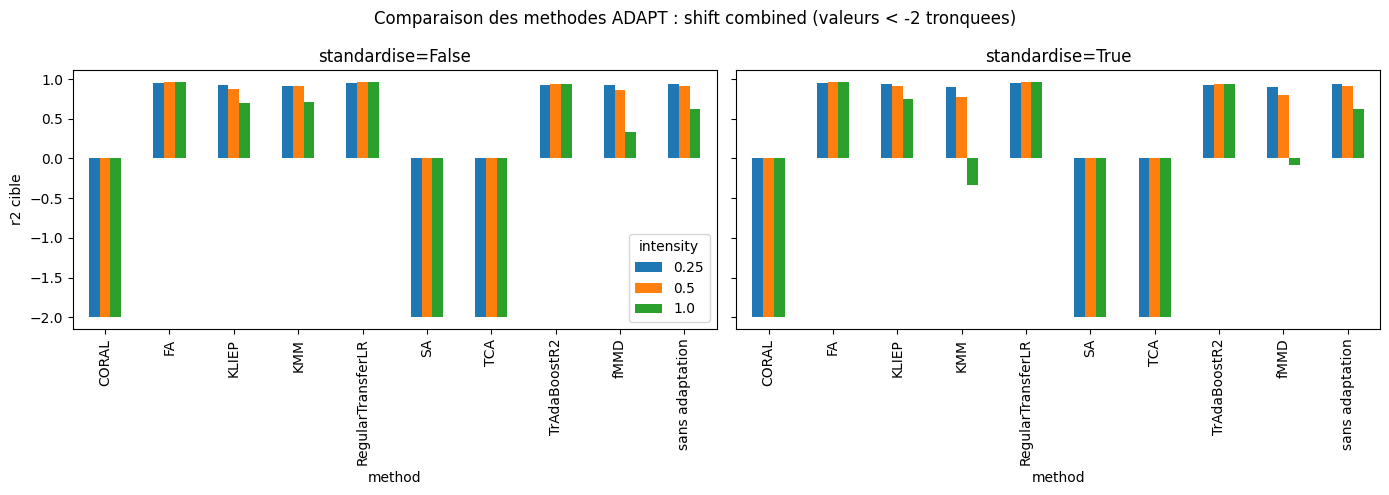

In [3]:
plot_floor = -2

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, standardise in zip(axes, [False, True]):
    subset = results_df[results_df["standardise"] == standardise]
    pivot = subset.pivot(index="method", columns="intensity", values="r2_target").clip(lower=plot_floor)
    pivot.plot(kind="bar", ax=ax, legend=(ax is axes[0]))
    ax.set_title(f"standardise={standardise}")
    ax.set_ylabel("r2 cible")

plt.suptitle(f"Comparaison des methodes ADAPT : shift {shift_type} (valeurs < {plot_floor} tronquees)")
plt.tight_layout()
plt.show()

## Source vs cible (sans standardisation)

In [4]:
subset = results_df[~results_df["standardise"]]
subset.pivot_table(index="method", columns="intensity", values=["r2_source", "r2_target"])

r2_source                         r2_target              \
intensity               0.25       0.50       1.00        0.25        0.50   
method                                                                       
CORAL               0.951031   0.951031   0.951031  -10.475380  -16.897553   
FA                  0.950920   0.950660   0.948893    0.950225    0.956905   
KLIEP               0.932321   0.922414   0.909202    0.919929    0.880220   
KMM                 0.925725   0.939011   0.913677    0.915721    0.917425   
RegularTransferLR   0.942740   0.918326   0.739809    0.950305    0.957060   
SA                  0.951031   0.951031   0.951031   -3.591124   -6.496176   
TCA               -11.144412 -62.192231 -11.360611 -102.036979 -957.592680   
TrAdaBoostR2        0.923731   0.884954   0.553042    0.920404    0.931966   
fMMD                0.945709   0.945709   0.945709    0.926622    0.864693   
sans adaptation     0.951031   0.951031   0.951031    0.940103    0.908212   

                                
intensity                 1.00  
method                          
CORAL               -29.930130  
FA                    0.960647  
KLIEP                 0.703729  
KMM                   0.705390  
RegularTransferLR     0.961330  
SA                  -12.353473  
TCA               -7910.362874  
TrAdaBoostR2          0.939390  
fMMD                  0.332037  
sans adaptation       0.619248

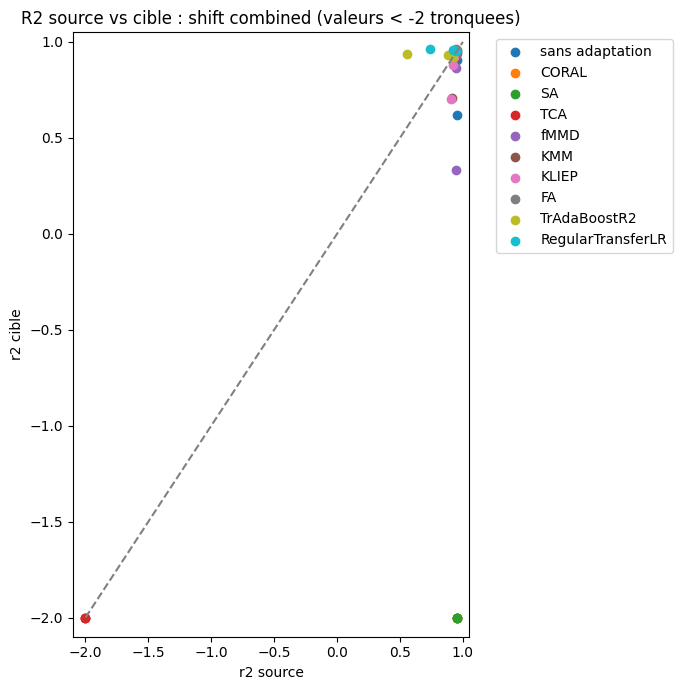

In [5]:
plot_floor = -2

fig, ax = plt.subplots(figsize=(7, 7))
for method in subset["method"].unique():
    method_data = subset[subset["method"] == method]
    x = method_data["r2_source"].clip(lower=plot_floor)
    y = method_data["r2_target"].clip(lower=plot_floor)
    ax.scatter(x, y, label=method)

ax.plot([plot_floor, 1], [plot_floor, 1], linestyle="--", color="gray")
ax.set_xlim(plot_floor - 0.1, 1.05)
ax.set_ylim(plot_floor - 0.1, 1.05)
ax.set_xlabel("r2 source")
ax.set_ylabel("r2 cible")
ax.set_title(f"R2 source vs cible : shift {shift_type} (valeurs < {plot_floor} tronquees)")
ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()